In [2]:
import pandas as pd

df = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_ncr_aqi_dataset.csv")

print(df.shape)
print(df.head())
print(df.info())

C:\Users\ASUS\AppData\Local\Temp\ipykernel_3936\58147706.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


(201664, 25)
              datetime        date  year  month  day  hour day_of_week  \
0  2020-01-01 06:00:00  2020-01-01  2020      1    1     6   Wednesday   
1  2020-01-01 12:00:00  2020-01-01  2020      1    1    12   Wednesday   
2  2020-01-01 18:00:00  2020-01-01  2020      1    1    18   Wednesday   
3  2020-01-01 23:00:00  2020-01-01  2020      1    1    23   Wednesday   
4  2020-01-01 06:00:00  2020-01-01  2020      1    1     6   Wednesday   

   is_weekend  season   city  ...    no2   so2    co    o3  temperature  \
0           0  winter  Delhi  ...  119.6  47.7  5.19  12.3          9.4   
1           0  winter  Delhi  ...  117.9  39.3  4.32  15.8         20.6   
2           0  winter  Delhi  ...  150.1  36.3  7.13  14.3         12.4   
3           0  winter  Delhi  ...  142.0  30.3  4.90  13.2         14.4   
4           0  winter  Delhi  ...  138.4  41.5  7.56  15.4          6.8   

   humidity  wind_speed  visibility  aqi  aqi_category  
0       100         3.6         1.

In [3]:
df = df[df["city"] == "Delhi"].copy()

print(df.shape)

(122752, 25)


In [4]:
print(df["station"].nunique())

14


In [5]:
print(df.groupby("datetime")["station"].count().head())

datetime
2020-01-01 06:00:00    14
2020-01-01 12:00:00    14
2020-01-01 18:00:00    14
2020-01-01 23:00:00    14
2020-01-02 06:00:00    14
Name: station, dtype: int64


In [6]:
print(df["station"].unique())

['Anand Vihar, Delhi' 'Jahangirpuri, Delhi' 'Wazirpur, Delhi'
 'Bawana, Delhi' 'ITO, Delhi' 'Punjabi Bagh, Delhi' 'Okhla Phase 2, Delhi'
 'Shadipur, Delhi' 'Rohini, Delhi' 'RK Puram, Delhi' 'Siri Fort, Delhi'
 'Dwarka Sec 8, Delhi' 'NSIT Dwarka, Delhi' 'Mandir Marg, Delhi']


In [7]:
print(df["station"].value_counts())

station
Anand Vihar, Delhi      8768
Jahangirpuri, Delhi     8768
Wazirpur, Delhi         8768
Bawana, Delhi           8768
ITO, Delhi              8768
Punjabi Bagh, Delhi     8768
Okhla Phase 2, Delhi    8768
Shadipur, Delhi         8768
Rohini, Delhi           8768
RK Puram, Delhi         8768
Siri Fort, Delhi        8768
Dwarka Sec 8, Delhi     8768
NSIT Dwarka, Delhi      8768
Mandir Marg, Delhi      8768
Name: count, dtype: int64


In [8]:
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime")

In [9]:
print(df.groupby("datetime").size().head())

datetime
2020-01-01 06:00:00    14
2020-01-01 12:00:00    14
2020-01-01 18:00:00    14
2020-01-01 23:00:00    14
2020-01-02 06:00:00    14
dtype: int64


In [10]:
agg_dict = {
    "pm25": "mean",
    "pm10": "mean",
    "no2": "mean",
    "so2": "mean",
    "co": "mean",
    "o3": "mean",
    "temperature": "mean",
    "humidity": "mean",
    "wind_speed": "mean",
    "visibility": "mean",
    "aqi": "mean"
}

In [11]:
time_cols = {
    "hour": "first",
    "day": "first",
    "month": "first",
    "day_of_week": "first",
    "is_weekend": "first",
    "season": "first"
}

In [12]:
agg_dict.update(time_cols)

In [13]:
df_agg = df.groupby("datetime").agg(agg_dict).reset_index()

In [14]:
print(df_agg.shape)
print(df_agg.head())

(8768, 18)
             datetime        pm25        pm10         no2        so2  \
0 2020-01-01 06:00:00  332.435714  630.200000  118.878571  28.671429   
1 2020-01-01 12:00:00  242.214286  461.600000   86.057143  20.542857   
2 2020-01-01 18:00:00  290.692857  551.642857  140.457143  27.442857   
3 2020-01-01 23:00:00  310.171429  594.085714  108.785714  26.078571   
4 2020-01-02 06:00:00  357.600000  648.535714  125.135714  29.257143   

         co         o3  temperature   humidity  wind_speed  visibility  \
0  5.247857  16.771429     8.071429  99.714286    3.107143    1.350000   
1  3.510714  24.192857    18.850000  55.928571    7.678571    2.300000   
2  6.100000  20.814286    14.228571  54.500000    5.285714    1.807143   
3  4.599286  19.357143    14.357143  53.428571    5.564286    1.385714   
4  5.409286  16.164286     8.085714  99.785714    3.114286    1.028571   

          aqi  hour  day  month day_of_week  is_weekend  season  
0  490.857143     6    1      1   Wednesday  

In [15]:
print(df_agg.isnull().sum())

datetime       0
pm25           0
pm10           0
no2            0
so2            0
co             0
o3             0
temperature    0
humidity       0
wind_speed     0
visibility     0
aqi            0
hour           0
day            0
month          0
day_of_week    0
is_weekend     0
season         0
dtype: int64


In [16]:
df_agg["day_of_week"] = df_agg["day_of_week"].astype("category").cat.codes
df_agg["season"] = df_agg["season"].astype("category").cat.codes

In [17]:
corr = df_agg.corr(numeric_only=True)

print(corr["aqi"].sort_values(ascending=False))

aqi            1.000000
season         0.817373
pm10           0.811968
pm25           0.811881
so2            0.802980
co             0.796769
no2            0.793679
month          0.112434
day            0.025572
hour           0.017791
day_of_week    0.005610
is_weekend    -0.038670
humidity      -0.238193
o3            -0.297696
wind_speed    -0.584925
temperature   -0.751759
visibility    -0.961166
Name: aqi, dtype: float64


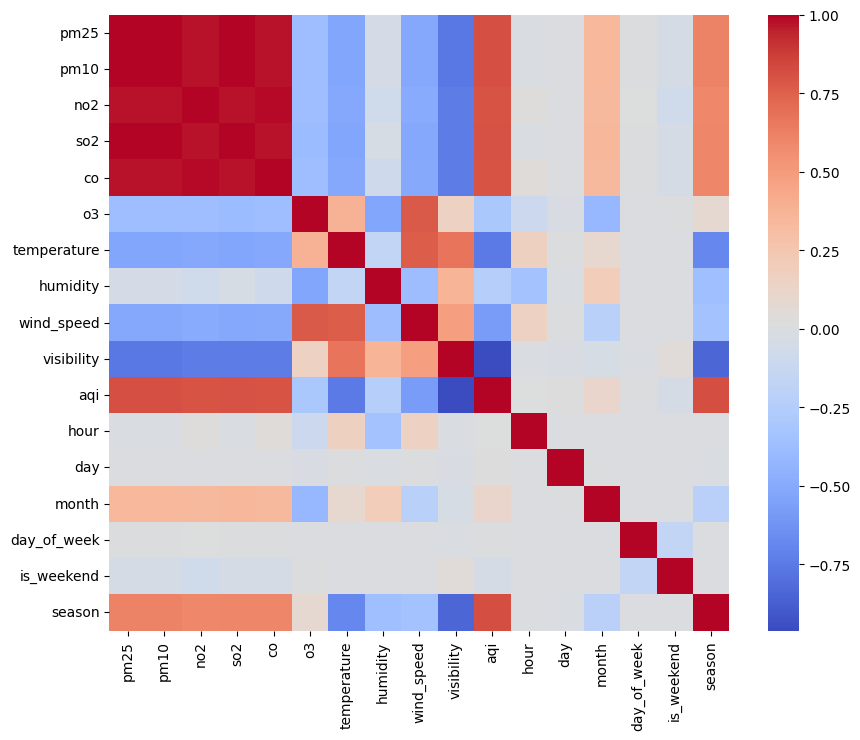

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap="coolwarm")
plt.show()

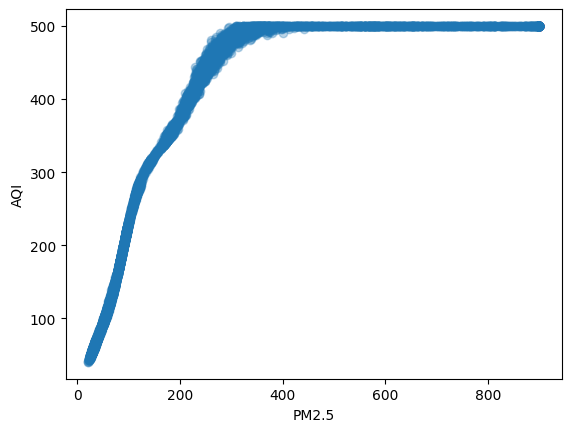

In [19]:
plt.scatter(df_agg["pm25"], df_agg["aqi"], alpha=0.3)
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.show()

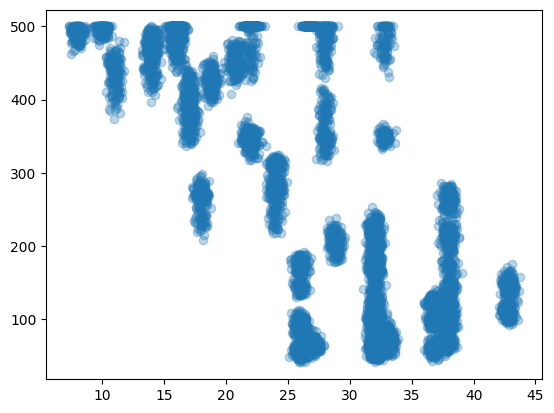

In [20]:
plt.scatter(df_agg["temperature"], df_agg["aqi"], alpha=0.3)
plt.show()

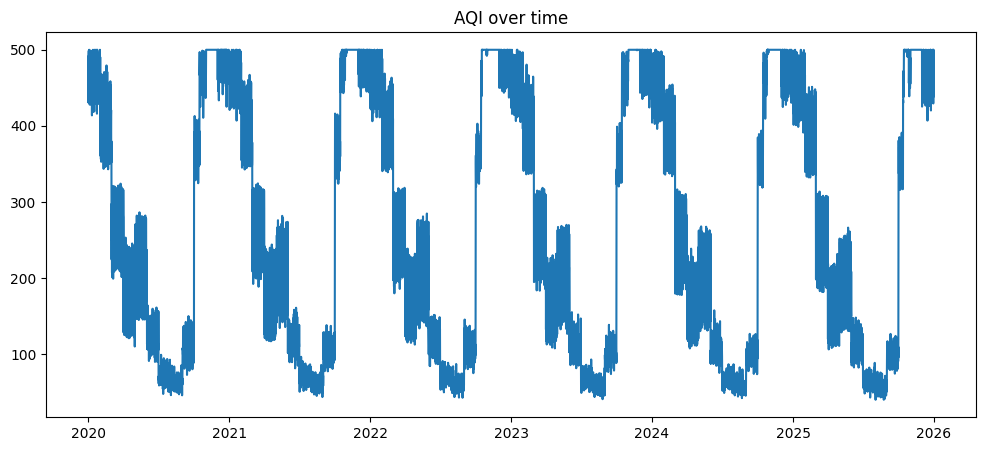

In [21]:
plt.figure(figsize=(12,5))
plt.plot(df_agg["datetime"], df_agg["aqi"])
plt.title("AQI over time")
plt.show()

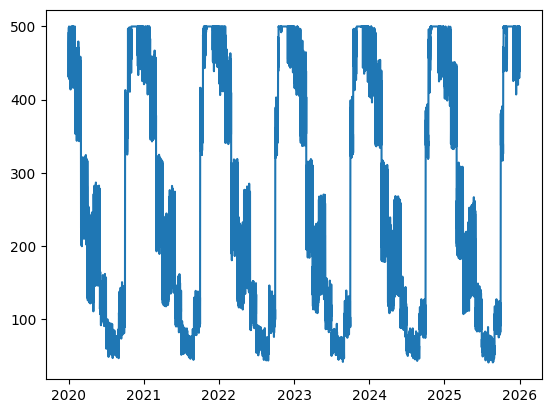

In [23]:
plt.plot(df_agg["datetime"], df_agg["aqi"])
plt.show()

In [24]:
df_agg["datetime"] = pd.to_datetime(df_agg["datetime"])
df_agg = df_agg.sort_values("datetime")

In [25]:
df_agg = df_agg.sort_values("datetime")

df_agg["aqi_lag1"] = df_agg["aqi"].shift(1)
df_agg["aqi_lag2"] = df_agg["aqi"].shift(2)
df_agg["aqi_lag3"] = df_agg["aqi"].shift(3)

df_agg = df_agg.dropna()


In [26]:
features = [
    "pm25", "pm10", "no2", "so2", "co", "o3",
    "temperature", "humidity", "wind_speed",
    "season",
    "aqi_lag1", "aqi_lag2", "aqi_lag3"
]

target = "aqi"

# BASIC FEATURES
features_basic = [
    "pm25", "pm10", "no2", "so2", "co", "o3"
]

# LAG FEATURES
features_lag = [
    "pm25", "pm10", "no2", "so2", "co", "o3",
    "aqi_lag1", "aqi_lag2", "aqi_lag3"
]

target = "aqi"

In [27]:
train_size = int(len(df_agg) * 0.8)

train = df_agg.iloc[:train_size]
test = df_agg.iloc[train_size:]

y_train = train["aqi"]
y_test = test["aqi"]

train = train.dropna()
test = test.dropna()

X_train = train[features_lag]
y_train = train["aqi"]

X_test = test[features_lag]
y_test = test["aqi"]

SIMPLEST MODEL LR 

In [28]:
# BASIC MODEL INPUT
X_train_basic = train[features_basic]
X_test_basic = test[features_basic]

# LAG MODEL INPUT
X_train_lag = train[features_lag]
X_test_lag = test[features_lag]

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr_basic = LinearRegression()
lr_lag = LinearRegression()

# train separately
lr_basic.fit(X_train_basic, y_train)
lr_lag.fit(X_train_lag, y_train)

# predictions bana
y_pred_basic = lr_basic.predict(X_test_basic)
y_pred_lag = lr_lag.predict(X_test_lag)

print("LR Basic R2:", r2_score(y_test, y_pred_basic))
print("LR Lag R2:", r2_score(y_test, y_pred_lag))

LR Basic R2: 0.6734849366055243
LR Lag R2: 0.973193996444599


RANDOM FOREST

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=42
)

rf.fit(X_train_lag, y_train)
y_pred_rf = rf.predict(X_test_lag)

print("RF R2:", r2_score(y_test, y_pred_rf))

RF R2: 0.9997168447360824


In [31]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["LR Basic", "LR Lag","Random Forest"],
    "R2 Score": [
        r2_score(y_test, y_pred_basic),
        r2_score(y_test, y_pred_lag),
        r2_score(y_test, y_pred_rf)
    ]
})

print(results)

           Model  R2 Score
0       LR Basic  0.673485
1         LR Lag  0.973194
2  Random Forest  0.999717


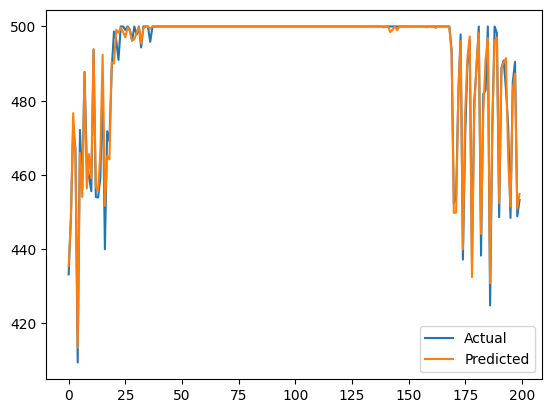

In [32]:
# The lag features significantly improve the performance of the linear regression model, and the random forest model performs even better.
#PLOT

import matplotlib.pyplot as plt

plt.plot(y_test.values[:200], label="Actual")
plt.plot(y_pred_rf[:200], label="Predicted")
plt.legend()
plt.show()

SVR- SUPPORT VECTOR REGRESSION

In [33]:
from sklearn.svm import SVR

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_lag)
X_test_scaled = scaler.transform(X_test_lag)

svr = SVR(kernel="rbf", C=100, gamma=0.1)

svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

from sklearn.metrics import r2_score, mean_squared_error

print("SVR R2:", r2_score(y_test, y_pred_svr))
print("SVR RMSE:", mean_squared_error(y_test, y_pred_svr)**0.5)


SVR R2: 0.9994765458351526
SVR RMSE: 4.026370218650858


ARIMA

In [34]:
ts = df_agg.set_index("datetime")["aqi"]
ts = ts.sort_index()
train_size = int(len(ts) * 0.8)

train_ts = ts[:train_size]
test_ts = ts[train_size:]

from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train_ts, order=(3,1,2))
model_arima_fit = model_arima.fit()

y_pred_arima = model_arima_fit.forecast(steps=len(test_ts))

print("ARIMA R2:", r2_score(test_ts, y_pred_arima))
print("ARIMA RMSE:", mean_squared_error(test_ts, y_pred_arima)**0.5)

c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


ARIMA R2: -0.704950477038929
ARIMA RMSE: 229.7895420768895


c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


SARIMA

In [35]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model_sarima = SARIMAX(
    train_ts,
    order=(2,1,2),
    seasonal_order=(1,1,1,12)   # try 12 or 24
)

model_sarima_fit = model_sarima.fit()

y_pred_sarima = model_sarima_fit.forecast(steps=len(test_ts))

print("SARIMA R2:", r2_score(test_ts, y_pred_sarima))
print("SARIMA RMSE:", mean_squared_error(test_ts, y_pred_sarima)**0.5)

c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


SARIMA R2: -211.72702178957746
SARIMA RMSE: 2566.762615780294


c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\AirVision\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [58]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# =========================
# HELPER FUNCTION
# =========================
def get_metrics(y_true, y_pred):
    return (
        round(r2_score(y_true, y_pred), 5),   
        round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),
        round(mean_absolute_error(y_true, y_pred), 3)
    )

# =========================
# 1. TRAIN PREDICTIONS
# =========================
y_train_pred_basic = lr_basic.predict(X_train_basic)
y_train_pred_lag   = lr_lag.predict(X_train_lag)
y_train_pred_rf    = rf.predict(X_train_lag)
y_train_pred_svr   = svr.predict(X_train_scaled)

# Time series (aligned)
y_train_pred_arima = model_arima_fit.predict(start=train_ts.index[0], end=train_ts.index[-1])
y_train_pred_sarima = model_sarima_fit.predict(start=train_ts.index[0], end=train_ts.index[-1])

# =========================
# 2. TEST PREDICTIONS
# =========================
y_pred_basic = lr_basic.predict(X_test_basic)
y_pred_lag   = lr_lag.predict(X_test_lag)
y_pred_rf    = rf.predict(X_test_lag)
y_pred_svr   = svr.predict(X_test_scaled)

# =========================
# 3. TRAIN RESULTS
# =========================
train_results = []

models_train = [
    ("Linear (Basic)", y_train, y_train_pred_basic),
    ("Linear (Lag)",   y_train, y_train_pred_lag),
    ("Random Forest",  y_train, y_train_pred_rf),
    ("SVR",            y_train, y_train_pred_svr),
    ("ARIMA",          train_ts, y_train_pred_arima),
    ("SARIMA",         train_ts, y_train_pred_sarima),
]

for name, y_true, y_pred in models_train:
    r2, rmse, mae = get_metrics(y_true, y_pred)
    train_results.append([name, r2, rmse, mae])

train_df = pd.DataFrame(train_results, columns=["Model", "R2", "RMSE", "MAE"])

print("\n===== TRAIN RESULTS =====")
print(train_df)

# =========================
# 4. TEST RESULTS
# =========================
test_results = []

models_test = [
    ("Linear (Basic)", y_test, y_pred_basic),
    ("Linear (Lag)",   y_test, y_pred_lag),
    ("Random Forest",  y_test, y_pred_rf),
    ("SVR",            y_test, y_pred_svr),
    ("ARIMA",          test_ts, y_pred_arima),
    ("SARIMA",         test_ts, y_pred_sarima),
]

for name, y_true, y_pred in models_test:
    r2, rmse, mae = get_metrics(y_true, y_pred)
    test_results.append([name, r2, rmse, mae])

test_df = pd.DataFrame(test_results, columns=["Model", "R2", "RMSE", "MAE"])

# sort by best model
test_df = test_df.sort_values(by="R2", ascending=False)

print("\n===== TEST RESULTS =====")
print(test_df)


===== TRAIN RESULTS =====
            Model       R2    RMSE     MAE
0  Linear (Basic)  0.66315  96.042  82.000
1    Linear (Lag)  0.96596  30.532  22.430
2   Random Forest  0.99992   1.472   0.859
3             SVR  0.99935   4.233   2.840
4           ARIMA  0.98271  21.761  13.151
5          SARIMA  0.98309  21.520  13.488

===== TEST RESULTS =====
            Model         R2      RMSE       MAE
2   Random Forest    0.99972     2.961     1.707
3             SVR    0.99948     4.026     2.678
1    Linear (Lag)    0.97319    28.813    20.999
0  Linear (Basic)    0.67348   100.560    86.427
4           ARIMA   -0.70495   229.790   178.003
5          SARIMA -211.72702  2566.763  2238.114


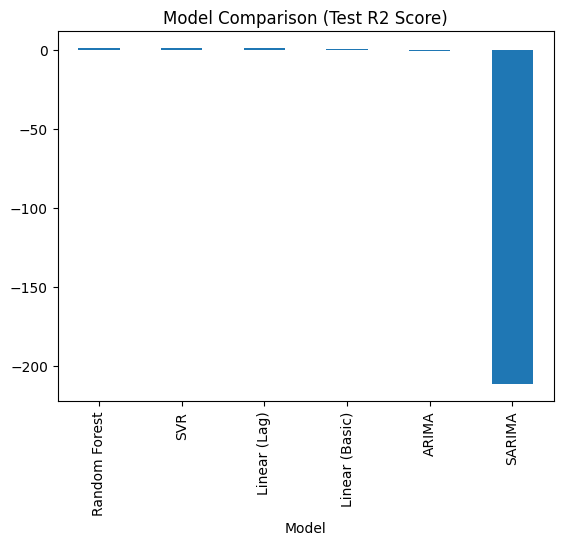

In [40]:
import matplotlib.pyplot as plt

test_results.set_index("Model")["R2"].plot(kind="bar")
plt.title("Model Comparison (Test R2 Score)")
plt.show()

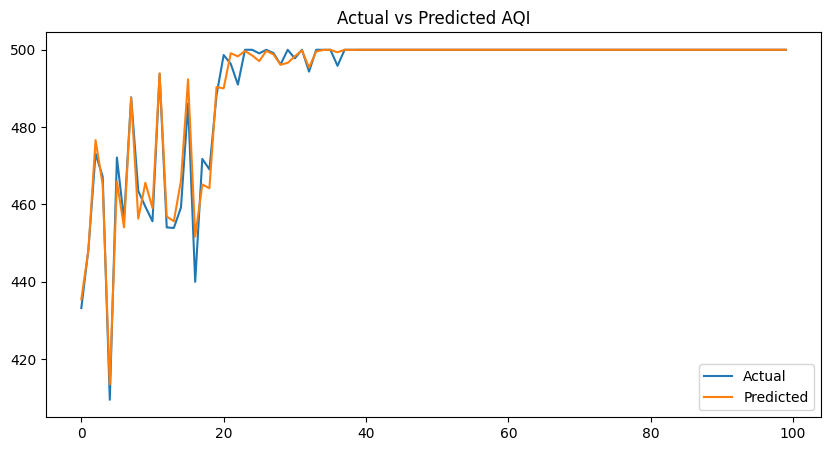

In [41]:
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:100], label="Actual")
plt.plot(y_pred_rf[:100], label="Predicted")
plt.legend()
plt.title("Actual vs Predicted AQI")
plt.show()

pm25        0.933725
pm10        0.066059
o3          0.000038
co          0.000033
so2         0.000033
no2         0.000032
aqi_lag1    0.000028
aqi_lag2    0.000026
aqi_lag3    0.000026
dtype: float64


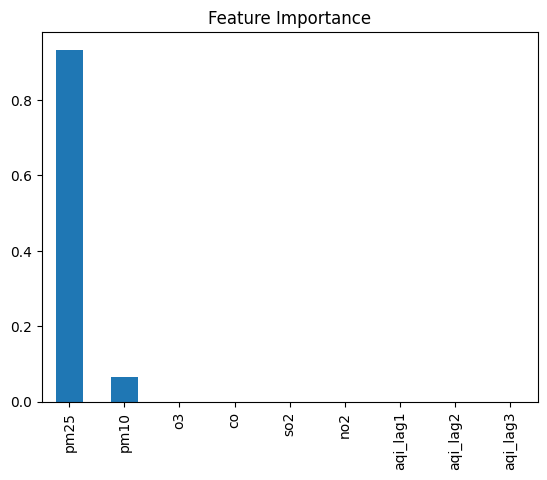

In [42]:
import pandas as pd

importance = pd.Series(rf.feature_importances_, index=features_lag)
importance = importance.sort_values(ascending=False)

print(importance)
importance.plot(kind="bar")
plt.title("Feature Importance")
plt.show()

GRADIENT BOOSTING

In [43]:
from sklearn.ensemble import GradientBoostingRegressor
gbr = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gbr.fit(X_train, y_train)
y_pred_gbr = gbr.predict(X_test)
print("GBR R2:", r2_score(y_test, y_pred_gbr))
print("GBR MAE:", mean_absolute_error(y_test, y_pred_gbr))
print("GBR RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gbr)))


GBR R2: 0.9997219236607258
GBR MAE: 1.841532881504519
GBR RMSE: 2.9346505499703315


In [44]:
y_train_pred_basic = lr_basic.predict(X_train_basic)
y_train_pred_lag = lr_lag.predict(X_train_lag)
y_train_pred_rf = rf.predict(X_train_lag)
y_train_pred_gbr = gbr.predict(X_train_lag)

In [45]:
train_results = pd.DataFrame({
    "Model": [
        "LR Basic",
        "LR Lag",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Train R2": [
        r2_score(y_train, y_train_pred_basic),
        r2_score(y_train, y_train_pred_lag),
        r2_score(y_train, y_train_pred_rf),
        r2_score(y_train, y_train_pred_gbr)
    ]
})

train_results = train_results.sort_values("Train R2", ascending=False).round(3)

print(train_results)

               Model  Train R2
2      Random Forest     1.000
3  Gradient Boosting     1.000
1             LR Lag     0.966
0           LR Basic     0.663


In [46]:
results = pd.DataFrame({
    "Model": [
        "LR Basic",
        "LR Lag",
        "Random Forest",
        "Gradient Boosting"
    ],
    "R2": [
        r2_score(y_test, y_pred_basic),
        r2_score(y_test, y_pred_lag),
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_gbr)
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_basic),
        mean_absolute_error(y_test, y_pred_lag),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_gbr)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_basic)),
        np.sqrt(mean_squared_error(y_test, y_pred_lag)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_gbr))
    ]
})

results = results.sort_values("R2", ascending=False)
results = results.round(3)

print(results)

               Model     R2     MAE     RMSE
3  Gradient Boosting  1.000   1.842    2.935
2      Random Forest  1.000   1.707    2.961
1             LR Lag  0.973  20.999   28.813
0           LR Basic  0.673  86.427  100.560


In [ ]:
import os

os.makedirs("models", exist_ok=True)
import joblib

# RANDOM FOREST
joblib.dump(rf, "models/rf_model.pkl")

# SVR
joblib.dump(svr, "models/svr_model.pkl")

# SCALER (important for SVR)
joblib.dump(scaler, "models/scaler.pkl")

# ARIMA
model_arima_fit.save("models/arima_model.pkl")

# SARIMA
model_sarima_fit.save("models/sarima_model.pkl")

In [ ]:
df_agg.to_csv("../delhi-aqi-prediction-using-ml/data/delhi_last_5_years.csv", index=False)

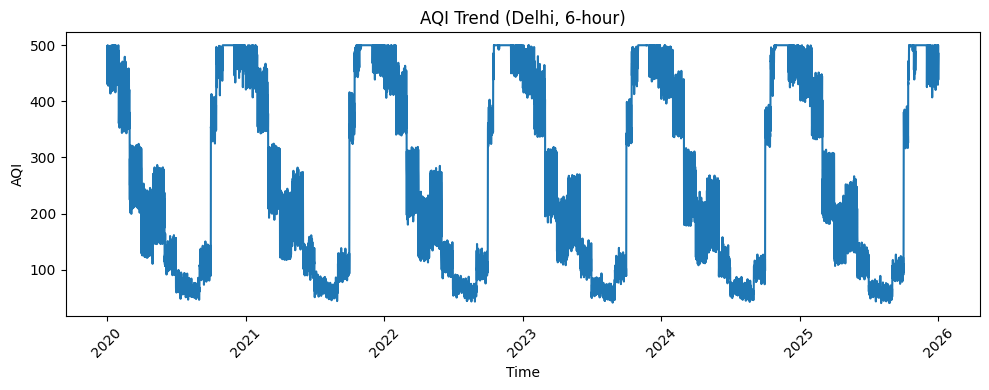

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df_agg["datetime"], df_agg["aqi"])
plt.title("AQI Trend (Delhi, 6-hour)")
plt.xlabel("Time")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

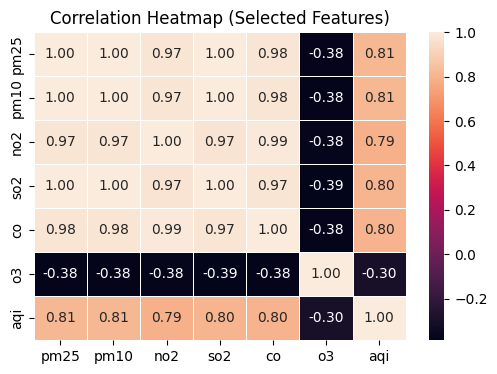

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["pm25", "pm10", "no2", "so2", "co", "o3", "aqi"]
corr = df_agg[cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Selected Features)")
plt.show()

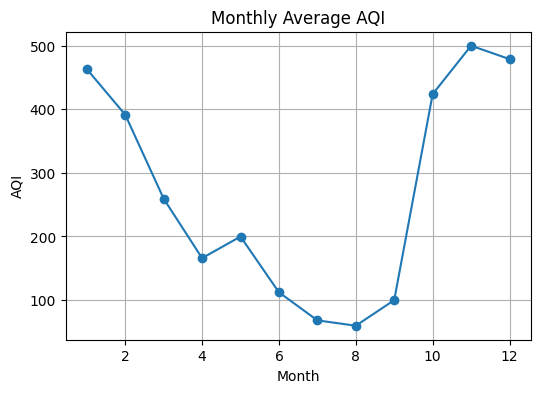

In [48]:
monthly = df_agg.groupby("month")["aqi"].mean()

plt.figure(figsize=(6,4))
monthly.plot(marker='o')
plt.title("Monthly Average AQI")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.grid()
plt.show()

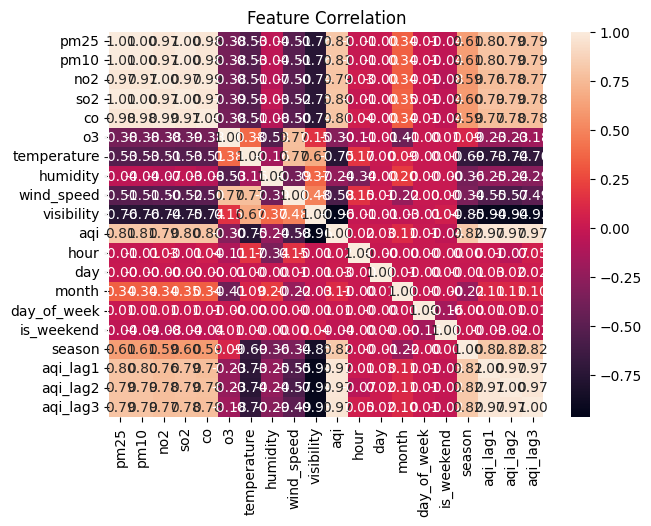

In [ ]:
import seaborn as sns

plt.figure(figsize=(7,5))
corr = df_agg.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt=".2f")
plt.title("Feature Correlation")
plt.show()

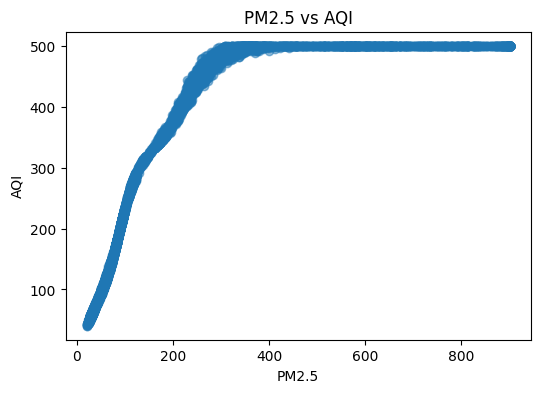

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df_agg["pm25"], df_agg["aqi"], alpha=0.5)
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.show()

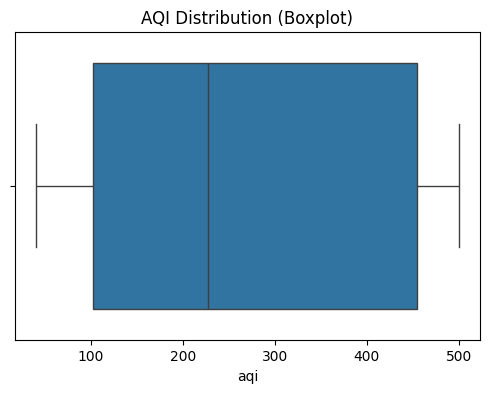

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df_agg["aqi"])
plt.title("AQI Distribution (Boxplot)")
plt.show()

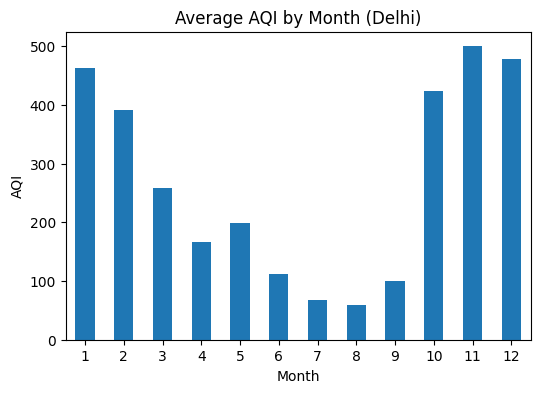

In [ ]:
monthly_avg = df_agg.groupby("month")["aqi"].mean()

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
monthly_avg.plot(kind="bar")
plt.title("Average AQI by Month (Delhi)")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.xticks(rotation=0)
plt.show()

    Feature  Importance
0      pm25    0.933725
1      pm10    0.066059
5        o3    0.000038
4        co    0.000033
3       so2    0.000033
2       no2    0.000032
6  aqi_lag1    0.000028
7  aqi_lag2    0.000026
8  aqi_lag3    0.000026


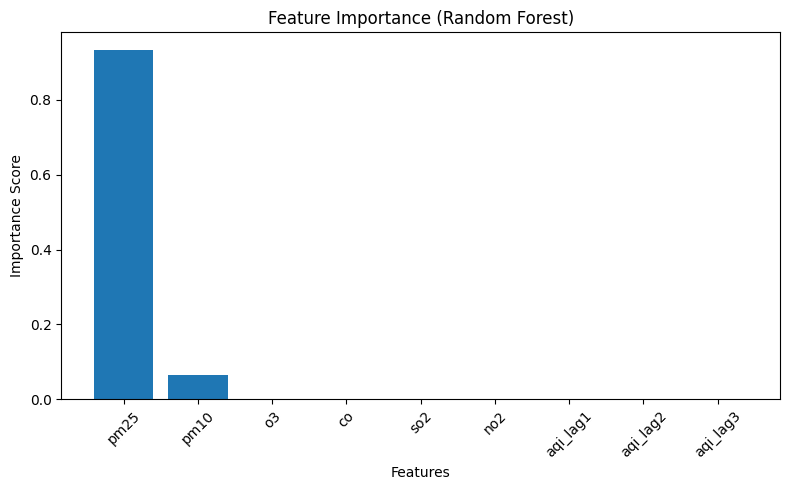

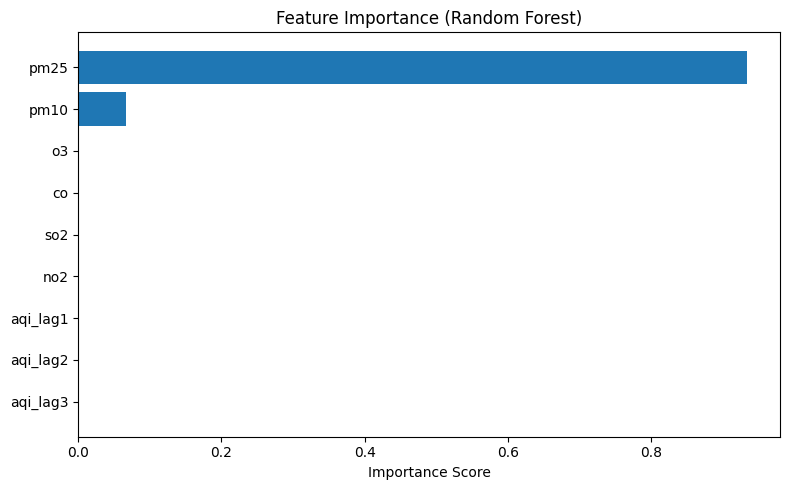

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# feature importance extract
importance = rf.feature_importances_

# dataframe bana
feature_imp_df = pd.DataFrame({
    "Feature": X_train_lag.columns,
    "Importance": importance
})

# sort karo
feature_imp_df = feature_imp_df.sort_values(by="Importance", ascending=False)

print(feature_imp_df)

# plot
plt.figure(figsize=(8,5))
plt.bar(feature_imp_df["Feature"], feature_imp_df["Importance"])
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.barh(feature_imp_df["Feature"], feature_imp_df["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

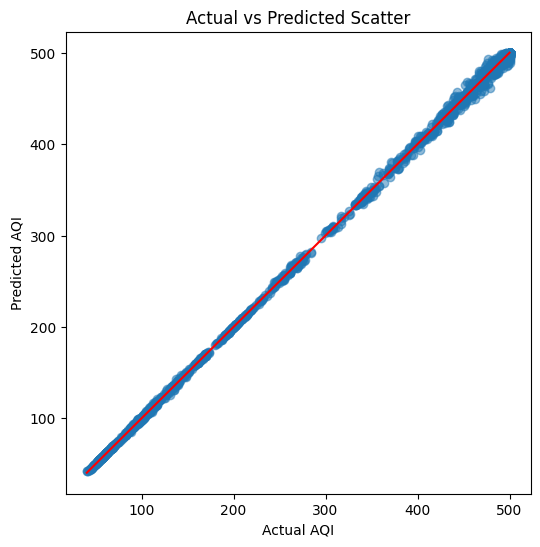

In [51]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.5)

# perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red')

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted Scatter")
plt.show()

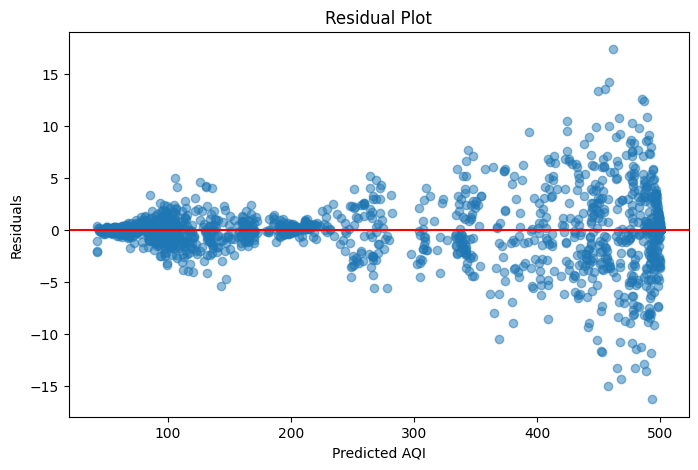

In [52]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(8,5))
plt.scatter(y_pred_rf, residuals, alpha=0.5)
plt.axhline(y=0, color='red')

plt.xlabel("Predicted AQI")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

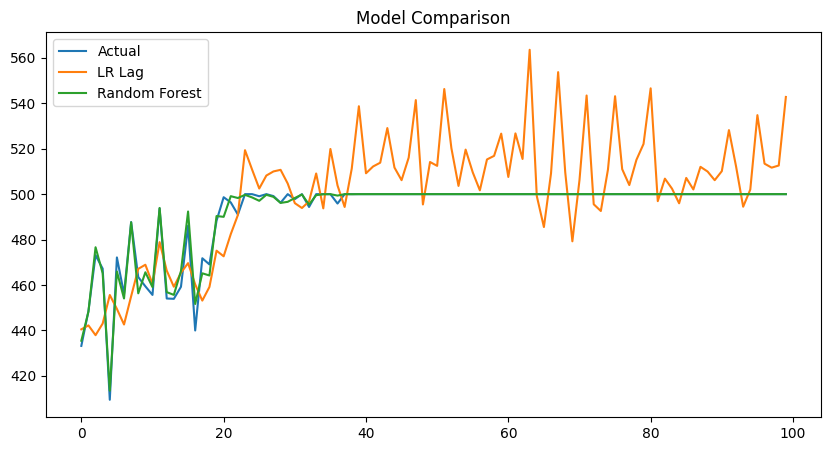

In [53]:
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:100], label="Actual")
plt.plot(y_pred_lag[:100], label="LR Lag")
plt.plot(y_pred_rf[:100], label="Random Forest")
plt.legend()
plt.title("Model Comparison")
plt.show()

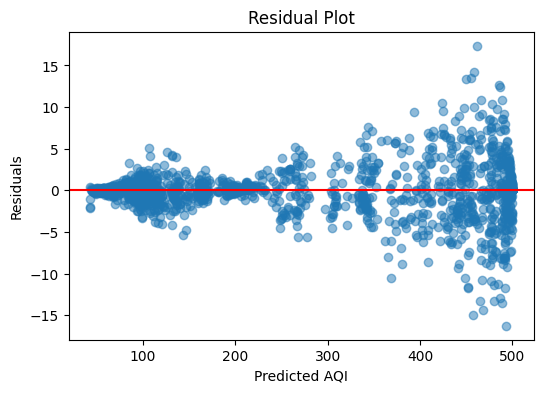

In [54]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(6,4))
plt.scatter(y_pred_rf, residuals, alpha=0.5)
plt.axhline(y=0, color='red')

plt.xlabel("Predicted AQI")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [60]:
import matplotlib.pyplot as plt

test_results.set_index("Model")["R2"].plot(kind="bar")
plt.title("Model Comparison (R2 Score)")
plt.ylabel("R2")
plt.xticks(rotation=30)
plt.show()

AttributeError: 'list' object has no attribute 'set_index'

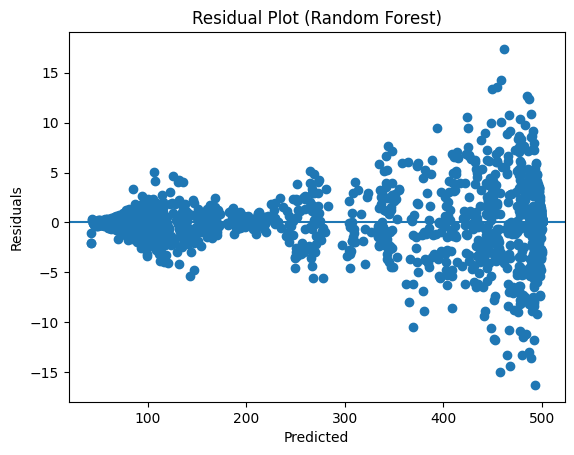

In [65]:
test_results = pd.DataFrame(test_results)
residuals = y_test.values - y_pred_rf

plt.figure()
plt.scatter(y_pred_rf, residuals)
plt.axhline(0)
plt.title("Residual Plot (Random Forest)")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()